# Grouped vs flat tables

Issue [#123](https://github.com/adkipnis/mixedbench/issues/123).

The sources from which MixedBench is built also include flat tables.<br>
In what other aspects do the flat tables differ from grouped ones?

- **Flat:** this includes each flat dataset's columns (except: response, id columns).
- **Grouped:** this includes each dataset's columns (except: response, id columns, grouping factors) of its first documented model.
- **Sizes:** rows, columns, design columns (K − 1 for a categorical of K levels), the design's condition index.
- **Type mix:** the shares of continuous, binary, categorical and ordered columns, and the median K of the categorical and ordered columns.
- **Column statistics:** the shares of missing values, outliers, zeros, minima, maxima, distinct values and the rarest level, skewness, excess kurtosis and the largest rank correlation with another column. Each summarized as a median over the table's columns.
- **Response:** the documented response of a flat table and of a grouped dataset's first model, by the same statistics and its type (continuous, binary, count, binomial, ordinal or categorical).
- **Test:** the two-sided Mann-Whitney U test per statistic.
- **Effect size:** the rank-biserial correlation $r$ (the probability that a grouped table lies above a flat one, minus the reverse probability).

`run.py` reads the measured files of mixedbench 1.0.12 and writes `tests.csv`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# tests.csv's statistics and columns as the text names them
NAMES = {
    'n_obs': 'rows',
    'n_columns': 'columns',
    'd_all': 'design columns',
    'condition_all': 'condition index',
    'continuous_share': 'continuous share',
    'binary_share': 'binary share',
    'categorical_share': 'categorical share',
    'ordered_share': 'ordered share',
    'K': 'levels K',
    'missing_share': 'missing share',
    'skewness': 'skewness',
    'excess_kurtosis': 'excess kurtosis',
    'outlier_share': 'outlier share',
    'zero_share': 'zero share',
    'min_share': 'minimum share',
    'max_share': 'maximum share',
    'unique_share': 'distinct share',
    'rare_level_share': 'rarest level share',
    'max_abs_rho': 'largest |rank correlation|',
    'response_K': 'levels K',
    'response_missing_share': 'missing share',
    'response_skewness': 'skewness',
    'response_excess_kurtosis': 'excess kurtosis',
    'response_outlier_share': 'outlier share',
    'response_zero_share': 'zero share',
    'response_min_share': 'minimum share',
    'response_max_share': 'maximum share',
    'response_unique_share': 'distinct share',
    'response_rare_level_share': 'rarest level share',
    'response_max_abs_rho': 'largest |rank correlation|',
    'response_continuous_share': 'continuous',
    'response_binary_share': 'binary',
    'response_count_share': 'count',
    'response_binomial_share': 'binomial',
    'response_ordinal_share': 'ordinal',
    'response_categorical_share': 'categorical',
}
COLUMNS = {
    'n_registry': 'grouped tables',
    'n_flat': 'flat tables',
    'median_registry': 'grouped median',
    'median_flat': 'flat median',
    'rank_biserial': 'r',
    'p': 'p',
    'p_holm': 'p (Holm)',
}


def adjustHolm(p: pd.Series) -> pd.Series:
    """Holm's step-down adjusted p-values (Holm 1979)."""
    ranked = p.sort_values()
    steps = np.arange(len(p), 0, -1)  # m, m − 1, ..., 1
    adjusted = np.minimum(np.maximum.accumulate(steps * ranked.to_numpy()), 1)
    return pd.Series(adjusted, index=ranked.index).reindex(p.index)


def tabulateTests(tests: pd.DataFrame) -> pd.DataFrame:
    table = tests.set_index('statistic')[list(COLUMNS)]
    for column in ('p', 'p_holm'):
        table[column] = table[column].map('{:.2g}'.format)
    return table.rename(index=NAMES, columns=COLUMNS)


tests = pd.read_csv('tests.csv')
tests['p_holm'] = adjustHolm(tests['p'])  # over every test of both flat sets and the response
responded = tests['statistic'].str.startswith('response_')
tabulateTests(tests[tests['flat'] == 'all'])

,grouped tables,flat tables,grouped median,flat median,r,p,p (Holm)
statistic,,,,,,,
rows,623,722,500.0000,74.5000,0.4659,3e-49,1.6e-47
columns,623,722,3.0000,4.0000,-0.1994,1.9e-10,8.2e-09
design columns,623,722,4.0000,5.0000,-0.0843,0.0073,0.2
condition index,593,698,4.0284,4.6520,-0.0920,0.0043,0.12
continuous share,586,714,0.5000,0.8370,-0.4153,2.2e-39,1.2e-37
binary share,586,714,0.2500,0.0000,0.2758,9.8e-20,4.7e-18
categorical share,586,714,0.0000,0.0000,0.1591,3e-09,1.3e-07
ordered share,586,714,0.0000,0.0000,0.0656,2.7e-09,1.1e-07
levels K,269,194,4.0000,4.0000,-0.0688,0.2,1


The response's tests take only the flat tables with a documented response.<br>
A type's row compares the share of responses of that type.

In [2]:
tabulateTests(tests[responded])

,grouped tables,flat tables,grouped median,flat median,r,p,p (Holm)
statistic,,,,,,,
levels K,161,83,2.0000,2.0000,-0.0044,0.95,1
missing share,623,353,0.0000,0.0000,0.0784,0.0001,0.0036
skewness,462,270,0.3278,0.4485,-0.0124,0.78,1
excess kurtosis,462,269,0.3087,0.1633,0.0595,0.18,1
outlier share,462,270,0.0000,0.0000,0.1109,0.0013,0.042
zero share,493,279,0.0000,0.0000,0.1069,0.0015,0.047
minimum share,501,287,0.0123,0.0278,-0.2400,2e-08,8e-07
maximum share,501,287,0.0060,0.0213,-0.3123,2.8e-13,1.3e-11
distinct share,623,353,0.1634,0.5321,-0.2469,1.4e-10,6.1e-09


## Effect sizes

Per statistic, $r$ over all flat tables vs. over the subset with a documented response.<br>
The response's statistics and types have only the subset.<br>
A grey $r$ is not significant after Holm's correction over every test.

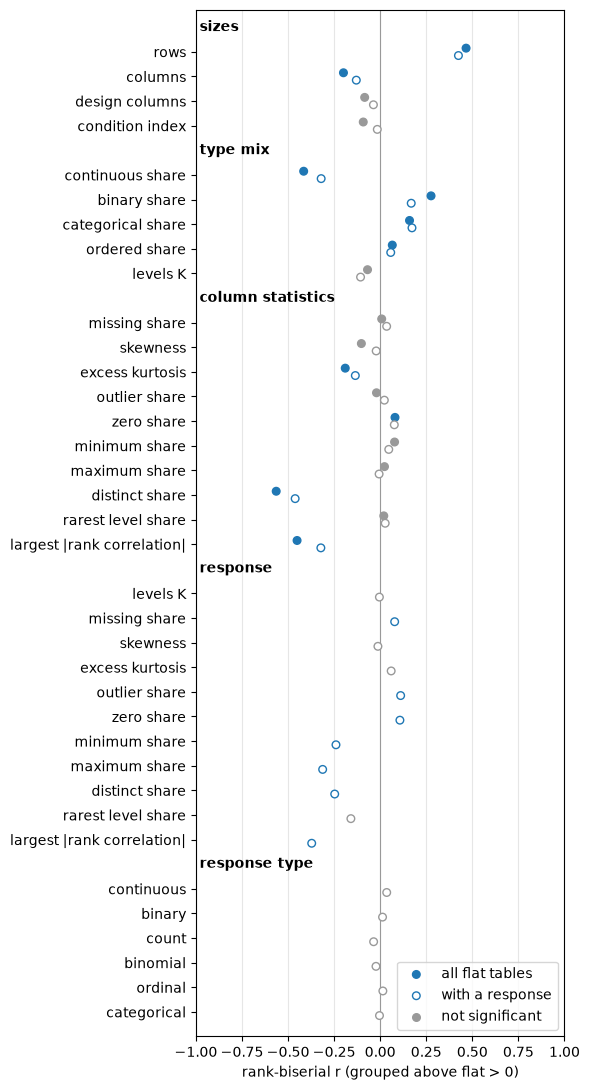

In [3]:
ALPHA = 0.05  # a Holm-adjusted p at or above it is grey
BLOCKS = {
    'sizes': 4,
    'type mix': 5,
    'column statistics': 10,
    'response': 11,
    'response type': 6,
}  # consecutive statistics of tests.csv
SIDES = {  # label, vertical offset, filled marker
    'all': ('all flat tables', -0.15, True),
    'response': ('with a response', 0.15, False),
}

statistics = tests['statistic'].unique()
r = tests.pivot(index='statistic', columns='flat', values='rank_biserial').loc[statistics]
p = tests.pivot(index='statistic', columns='flat', values='p_holm').loc[statistics]
y = []  # a row per statistic, a heading row above each block
headings = {}
row = 0
for name, count in BLOCKS.items():
    headings[name] = row
    y.extend(range(row + 1, row + 1 + count))
    row += count + 1
y = np.array(y)

fig, ax = plt.subplots(figsize=(6, 11))
ax.axvline(0, color='0.6', linewidth=0.8)
for side, (label, offset, filled) in SIDES.items():
    color = np.where(p[side] < ALPHA, 'C0', '0.6')
    face = color if filled else 'white'
    ax.scatter(r[side], y + offset, s=30, edgecolors=color, facecolors=face, label=label, zorder=3)
ax.scatter([], [], s=30, color='0.6', label='not significant')
for name, row in headings.items():
    ax.text(-0.98, row, name, va='center', fontweight='bold')
ax.set(
    xlim=(-1, 1),
    ylim=(y[-1] + 1, -0.7),
    yticks=y,
    yticklabels=[NAMES[s] for s in statistics],
    xlabel='rank-biserial r (grouped above flat > 0)',
)
ax.grid(axis='x', color='0.9')
ax.set_axisbelow(True)
ax.legend(loc='lower right')
fig.tight_layout()
fig.savefig('effects.pdf')

## Finding

**Grouped and flat tables differ most in size, type mix and how distinct their values are:**
1. Grouped tables have more rows and more binary and categorical columns. Flat tables more continuous ones.
2. Flat tables' columns hold more distinct values and correlate more strongly.
3. Skewness, outliers, extremes and missing values barely differ.
4. The size of the effect slightly shrinks when discarding tables without a documented response.
5. The responses differ as the columns do, in how distinct their values are and how strongly they correlate, and flat responses sit more often at their extremes. Their types, levels, skewness and kurtosis do not differ.